# Research foundations: saved inputs to a research dataset

For researchers with saved OKX historical L2 and Bitfinex R0 recordings, this
walkthrough answers five questions:

1. What visible liquidity can I reconstruct, and which clocks are available?
2. How do separate saved inputs flow through admission into one reproducible dataset?
3. Which revisions and membership assertions were known at a decision cutoff?
4. Can I consume bounded price batches without losing controls or replay history?
5. Does the reference reader meet the measured one-hour trade-inspection workload?

The book exploration uses real saved inputs. The dataset walkthrough uses **small
synthetic trades**, because published LOB adapters are planned for MR 25. Everything
here runs offline, without credentials. If inputs are missing, first use
[market-data-capture.ipynb](market-data-capture.ipynb); see the
[operations guide](notebook-operations.md) for installation and pinned input paths.

Restart the kernel and **Run All in order**. Expand the collapsed setup cells only
when needed. These observations do not replace the [frozen P1 study](../docs/research/p1-baseline.md)
or establish coverage, fills or a strategy result.

## 1. Identify this execution

The installed package must match the checkout and pinned interpreter. The table
records code, configuration and notebook fingerprints for comparing later runs.

In [1]:
# standard library imports
import hashlib
import json
import os
import platform
import subprocess
import sys
from datetime import UTC, datetime, timedelta
from decimal import Decimal
from html import escape
from importlib.metadata import distributions, version
from pathlib import Path

# third party library imports
from IPython.display import HTML, display

# project library imports
import alpha_research
from alpha_research.data.live.config import CaptureConfig, CaptureRequest
from alpha_research.data.live.journal import CaptureJournal, CaptureRecord
from alpha_research.data.live.replay import CaptureReplay
from alpha_research.data.raw_objects import RawObject
from alpha_research.data.venues.bitfinex.book import BitfinexBook
from alpha_research.data.venues.okx.history_config import OKXArchiveRequest, OKXHistoryConfig
from alpha_research.data.venues.okx.history_store import OKXArchiveStore
from alpha_research.serialization import DomainCodec

root = Path.cwd().resolve()
if root.name == "examples":
    root = root.parent
assert (root / "configs/history/okx-btc-usdt.json").is_file(), (
    "Run from the repository root or examples/."
)
notebook_path = Path(
    os.environ.get("ALPHA_RESEARCH_NOTEBOOK_PATH", root / "examples/research-foundations.ipynb")
).resolve()


class NotebookDisplay:
    """Render small tables for the exploratory notebook scenarios."""

    @staticmethod
    def show_table(headers: tuple[str, ...], rows: list[tuple[object, ...]]) -> None:
        """Display a small escaped table without adding a dataframe dependency.

        Args:
            headers: Column labels.
            rows: Exact or presentation values to render as text.
        """
        heading = "".join(
            f'<th style="text-align:left;padding:6px">{escape(label)}</th>' for label in headers
        )
        body = "".join(
            "<tr>"
            + "".join(
                f'<td style="padding:6px;vertical-align:top">{escape(str(value))}</td>'
                for value in row
            )
            + "</tr>"
            for row in rows
        )
        display(HTML(f"<table><thead><tr>{heading}</tr></thead><tbody>{body}</tbody></table>"))

In [2]:
assert platform.python_version() == (root / ".python-version").read_text().strip() == "3.14.7"
installed = Path(alpha_research.__file__).resolve().parent
assert "site-packages" in installed.parts and installed != root / "src/alpha_research"
source_root = root / "src/alpha_research"
runtime_files = sorted(
    path
    for path in source_root.rglob("*")
    if path.is_file() and path.suffix in {".py", ".json", ".typed"}
)
assert runtime_files
installed_runtime_paths = {
    path.relative_to(installed)
    for path in installed.rglob("*")
    if path.is_file() and path.suffix in {".py", ".json", ".typed"}
}
assert installed_runtime_paths == {path.relative_to(source_root) for path in runtime_files}, (
    "Installed runtime contains missing or extra files; use a clean candidate environment."
)
runtime_digest = hashlib.sha256()
for source_file in runtime_files:
    relative = source_file.relative_to(source_root)
    source_bytes = source_file.read_bytes()
    assert source_bytes == (installed / relative).read_bytes(), f"Stale installed file: {relative}"
    runtime_digest.update(str(relative).encode() + b"\0" + source_bytes + b"\0")

commit = subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=root, text=True).strip()
branch = subprocess.check_output(["git", "branch", "--show-current"], cwd=root, text=True).strip()
working_status = subprocess.check_output(["git", "status", "--short"], cwd=root, text=True).strip()
candidate_diff = subprocess.check_output(
    [
        "git",
        "diff",
        "--binary",
        "HEAD",
        "--",
        "src",
        "configs",
        "pyproject.toml",
        "uv.lock",
        ".python-version",
    ],
    cwd=root,
)
notebook_document = json.loads(notebook_path.read_text())
notebook_source = [
    (cell["cell_type"], "".join(cell["source"])) for cell in notebook_document["cells"]
]
notebook_digest = hashlib.sha256(
    json.dumps(notebook_source, ensure_ascii=False, separators=(",", ":")).encode()
).hexdigest()
identity = {
    "notebook_path": str(notebook_path),
    "attempt_id": os.environ.get("ALPHA_RESEARCH_ATTEMPT_ID", "interactive: unsnapshotted"),
    "commit": commit,
    "branch": branch,
    "working_tree": "changed" if working_status else "clean",
    "python": platform.python_version(),
    "platform": platform.platform(),
    "kernel": sys.executable,
    "package": str(installed),
    "verified_runtime_files": len(runtime_files),
    "runtime_sha256": runtime_digest.hexdigest(),
    "runtime_input_diff_sha256": hashlib.sha256(candidate_diff).hexdigest(),
    "uv_lock_sha256": hashlib.sha256((root / "uv.lock").read_bytes()).hexdigest(),
    "okx_config_sha256": hashlib.sha256(
        (root / "configs/history/okx-btc-usdt.json").read_bytes()
    ).hexdigest(),
    "notebook_source_sha256": notebook_digest,
    "notebook_tooling": {
        item.metadata["Name"]: version(item.metadata["Name"])
        for item in distributions()
        if item.metadata["Name"] in {"nbclient", "nbformat", "ipykernel", "matplotlib"}
    },
}
NotebookDisplay.show_table(("Identity", "Observed value"), list(identity.items()))

Identity,Observed value
notebook_path,/private/tmp/alpha-mr16-handoff/examples/research-foundations.ipynb
attempt_id,4aac3e54-ca95-45ce-b04f-b5ea386962cc
commit,4308a5a195efbe08dee10106e5d7db245e3049c4
branch,codex/mr-16-handoff-merge
working_tree,changed
python,3.14.7
platform,macOS-27.0-arm64-arm-64bit-Mach-O
kernel,/private/tmp/mr16-merge-validation/installed/venv/bin/python
package,/private/tmp/mr16-merge-validation/installed/venv/lib/python3.14/site-packages/alpha_research
verified_runtime_files,76


## 2. Select the saved books

Pin `ALPHA_OKX_ARCHIVE_DIRECTORY` and `ALPHA_BITFINEX_CAPTURE_DIRECTORY` to repeat
an observation. Otherwise, this selects the latest completed input matching each
maintained configuration. The printed paths identify this convenience selection;
it is not yet a published research dataset. Invalid or absent inputs fail visibly.

In [3]:
codec = DomainCodec()
okx_config = OKXHistoryConfig.read(root / "configs/history/okx-btc-usdt.json")
bitfinex_config = CaptureConfig.read(root / "configs/live/bitfinex-btc-usd.json")
selected = {}
selection_rows = []
for venue, folder, variable, request_type, config in (
    ("okx", "data/okx/history", "ALPHA_OKX_ARCHIVE_DIRECTORY", OKXArchiveRequest, okx_config),
    (
        "bitfinex",
        "data/bitfinex",
        "ALPHA_BITFINEX_CAPTURE_DIRECTORY",
        CaptureRequest,
        bitfinex_config,
    ),
):
    override = os.environ.get(variable)
    candidates = []
    paths = (
        [Path(override).expanduser()]
        if override
        else [p.parent for p in (root / folder).glob("*/manifest.json")]
    )
    for path in paths:
        request = codec.decode_json((path / "request.json").read_bytes(), request_type)
        if request.config != config:
            if override:
                raise ValueError(f"{variable} differs from the maintained selection")
            continue
        descriptor = codec.decode_json((path / "manifest.json").read_bytes(), RawObject)
        candidates.append((descriptor.ts_ingested, str(path.resolve()), request, descriptor))
    if not candidates:
        raise FileNotFoundError(f"No matching {venue} input; run market-data-capture.ipynb first")
    _, location, request, descriptor = max(candidates, key=lambda item: (item[0], item[1]))
    selected[venue] = (Path(location), request, descriptor)
    selection_rows.extend(
        [
            (
                venue,
                "Selection",
                "explicit directory" if override else "latest matching saved input",
            ),
            (venue, "Directory", location),
            (venue, "Raw SHA-256", descriptor.sha256),
            (venue, "Request identity", request.identity),
            (venue, "Original implementation SHA-256", request.implementation_identity),
        ]
    )
NotebookDisplay.show_table(("Source", "Evidence", "Value"), selection_rows)

Source,Evidence,Value
okx,Selection,explicit directory
okx,Directory,/Users/lxg/Documents/GitHub/Alpha Research/alpha-research-lab-private/data/okx/history/802967bb-05eb-4b7b-9c90-2c964f22e41f
okx,Raw SHA-256,fef59b343d1972c32f67583edc538c5d2f7350e6f3a0059e6f87896d7e8bf676
okx,Request identity,71672efd00a8f3f6c959d0a08f8ce2a8793b3fb84d23f1a3c22b2756a6ec2665
okx,Original implementation SHA-256,22c0e38d88691bd0b1141588260465c471bbde0ff432a6bd1d0dab0505000014
bitfinex,Selection,explicit directory
bitfinex,Directory,/Users/lxg/Documents/GitHub/Alpha Research/alpha-research-lab-private/data/bitfinex/a5116c5a-b7d6-4e2b-9ee6-c79839c80f43
bitfinex,Raw SHA-256,a57ddabc5b1283c702ee2c7fd104a2b9cd943e2b41661cfc1d66619b35930163
bitfinex,Request identity,0e1453a2e7e925ad5bc1454a6a7d1e7298eca46e82a0d07b10e7ad8fc1c9ec21
bitfinex,Original implementation SHA-256,22c0e38d88691bd0b1141588260465c471bbde0ff432a6bd1d0dab0505000014


## 3. Reconstruct and inspect visible liquidity

**OKX BTC-USDT:** verify the historical archive for 8 September 2026 and reconstruct
its first **10,000 records**. L2 aggregates size at each price; it supplies no
individual order identity. This reader returns a summary, not a historical price table.

In [4]:
okx_directory, okx_request, okx_descriptor = selected["okx"]
history = OKXArchiveStore(okx_directory).replay()
assert history["source_sequence"] is None and history["gaps"] is None
epoch = datetime(1970, 1, 1, tzinfo=UTC)
history_rows = [
    (key, history[key])
    for key in (
        "symbol",
        "representation",
        "records",
        "snapshots",
        "updates",
        "levels",
        "depth",
        "state_available",
        "continuity",
        "stop_reason",
        "entire_archive_replayed",
    )
]
for key in ("first_source_ms", "last_source_ms"):
    value = history[key]
    history_rows.append(
        (
            key.replace("_ms", "_utc"),
            None if value is None else epoch + timedelta(milliseconds=int(value)),
        )
    )
NotebookDisplay.show_table(("Historical observation", "Result"), history_rows)

Historical observation,Result
symbol,BTC-USDT
representation,L2
records,10000
snapshots,1
updates,9999
levels,800
depth,400
state_available,True
continuity,unproven_no_source_sequences
stop_reason,record_limit


`gaps=None` means continuity is unknown because the archive has no source sequence
numbers. An available reconstructed state does not prove uninterrupted coverage.

**Bitfinex BTC/USD:** replay the saved bounded R0 recording, then inspect the nearest
three individual orders on each side. Prices and spreads are USD per BTC; sizes
are BTC. Configured depth 25 and the number of retained orders are different measures.
The spread describes this recording and does not account for execution costs.

In [5]:
bitfinex_directory, bitfinex_request, bitfinex_descriptor = selected["bitfinex"]
replay = CaptureReplay.read(bitfinex_directory)
summary = replay.summary()
assert isinstance(replay.book, BitfinexBook)
live_rows = [
    (key, summary[key])
    for key in (
        "symbol",
        "messages",
        "snapshots",
        "updates",
        "orders",
        "depth",
        "gaps",
        "synchronized",
        "source_sequence",
        "last_source_time",
    )
]
for key in ("started_ns", "finished_ns"):
    live_rows.append(
        (key.replace("_ns", "_utc"), epoch + timedelta(microseconds=summary[key] // 1000))
    )
NotebookDisplay.show_table(("Recorded observation", "Result"), live_rows)
assert summary["synchronized"] and not summary["gaps"], (
    "This sample is unsuitable for the uninterrupted-book preview; inspect its gaps"
)

preview_rows = []
best = {}
for side in ("buy", "sell"):
    orders = sorted(
        (order for order in replay.book.orders.values() if order.side == side),
        key=lambda order: order.price,
        reverse=side == "buy",
    )
    assert orders, f"No observed {side} side"
    best[side] = orders[0].price
    for order in orders[:3]:
        assert isinstance(order.price, Decimal) and isinstance(order.size, Decimal)
        preview_rows.append((side, order.order_id, str(order.price), str(order.size)))
NotebookDisplay.show_table(("Side", "Visible order ID", "USD / BTC", "BTC"), preview_rows)
NotebookDisplay.show_table(
    ("Measure", "USD / BTC"),
    [
        ("Best bid", best["buy"]),
        ("Best ask", best["sell"]),
        ("Observed spread", best["sell"] - best["buy"]),
    ],
)

Recorded observation,Result
symbol,tBTCUSD
messages,376
snapshots,1
updates,371
orders,50
depth,25
gaps,[]
synchronized,True
source_sequence,373
last_source_time,None


Side,Visible order ID,USD / BTC,BTC
buy,244232632883,75645,0.00180442
buy,244230114777,75639,0.0002
buy,244218842321,75638,0.0002
sell,244216587539,75655,0.00022
sell,244232116576,75660,0.03522185
sell,244217678512,75660,0.00022


Measure,USD / BTC
Best bid,75645
Best ask,75655
Observed spread,10


## 4. Check clocks and repeatability

OKX supplies historical event timestamps but no historical receipt clock. Bitfinex
R0 supplies local receipt order but no exchange timestamp in these messages. Their
quote currencies, times and depths differ; **USD is not USDT** and these are not
simultaneous price observations. UTC display truncates journal nanoseconds to microseconds.

Replaying the same bytes must reproduce the same state trace. The final control
injects a disconnect into a separate replay: the book becomes unavailable until
resynchronization, instead of carrying stale quotes across the gap.

In [6]:
NotebookDisplay.show_table(
    ("Sample", "Source clock", "Local receipt evidence", "Saved bytes"),
    [
        (
            "OKX historical BTC-USDT",
            "Unix milliseconds in records; continuity unknown",
            f"Archive received {history['download_received']}; per-record receipt absent",
            history["saved_bytes"],
        ),
        (
            "Bitfinex recorded BTC/USD",
            "Absent in R0 messages",
            f"Journal nanoseconds {summary['started_ns']} to {summary['finished_ns']}",
            bitfinex_descriptor.size_bytes,
        ),
    ],
)

again = CaptureReplay.read(bitfinex_directory)
assert again.summary()["trace_identity"] == summary["trace_identity"]
exercise = CaptureReplay(bitfinex_config)
for record in CaptureJournal(bitfinex_directory, bitfinex_request).records():
    if record.kind == "end":
        break
    exercise.apply(record)
exercise.apply(
    CaptureRecord(
        kind="gap",
        epoch=exercise.epoch,
        received_ns=exercise.finished_ns,
        reason="synthetic_disconnect",
    )
)
assert not exercise.book.ready
NotebookDisplay.show_table(
    ("Check", "Observed result"),
    [
        ("Repeated state trace", summary["trace_identity"]),
        ("Injected disconnect", f"Book usable: {exercise.book.ready}"),
    ],
)

Sample,Source clock,Local receipt evidence,Saved bytes
OKX historical BTC-USDT,Unix milliseconds in records; continuity unknown,Archive received 2026-09-16T08:49:14.475436+00:00; per-record receipt absent,109423187
Bitfinex recorded BTC/USD,Absent in R0 messages,Journal nanoseconds 1789548508888411000 to 1789548529076738000,52908


Check,Observed result
Repeated state trace,283533b937763c40d108517fc22ddbbc2d10a77820a8de498cc631f37c11d375
Injected disconnect,Book usable: False


## 5. Prepare separate inputs for one dataset

The archive workflow is:

**saved acquisitions + per-input evidence → admission and assembly → atomic publication → verified reading**

`DatasetInput` carries each acquisition's quality policy, eligibility history and
correction evidence. Assembly retains the source, stream and instrument of every
partition. It is the composition boundary for future combinations of LOB sources;
those streams will remain separate within the dataset.

Today the installed saved-input adapter supports trade archives. This offline
example creates two **synthetic** instrument inputs using that adapter, with an
intentional duplicate in the first input. The CSV construction below is fixture
setup; the publication calls use the generic API. Actual LOB publication waits for
MR 25. The real OKX and Bitfinex recordings above are not published here.

In [7]:
# standard library imports
from tempfile import TemporaryDirectory
from zipfile import ZIP_DEFLATED, ZipFile, ZipInfo

# third party library imports
from msgspec.structs import replace

# project library imports
from alpha_research.configuration import Configuration
from alpha_research.data.asof import AsOfSelector
from alpha_research.data.datasets import DatasetInput
from alpha_research.data.eligibility import EligibilityAssertions
from alpha_research.data.manifests import AcquisitionManifest
from alpha_research.data.quality import QualityPolicy
from alpha_research.data.raw_store import RawStore
from alpha_research.data.requests import SourceRequest
from alpha_research.data.snapshots import SnapshotStore
from alpha_research.pipelines.dataset import publish_dataset
from alpha_research.reference_data import CatalogSnapshot

archive_catalog = codec.decode_json(
    (root / "configs/reference/binance-archive-spot.json").read_bytes(), CatalogSnapshot
)
archive_run = Configuration.read(root / "configs/data-jobs/binance-archive.json").resolve(
    "btc-archive", archive_catalog
)
eligibility = EligibilityAssertions.read(
    root / "tests/fixtures/mr12/eligibility.json", catalog=archive_catalog
)
start = archive_run.job.start
policy = QualityPolicy(use="exploratory", known_at=start, max_gap=timedelta(hours=1))
max_bytes = 262_144
acquired_at = datetime(2026, 9, 17, tzinfo=UTC)
workspace = TemporaryDirectory(prefix="research-dataset-")
local = Path(workspace.name)
raw_directory, destination = local / "raw", local / "snapshots"
raw_directory.mkdir()
destination.mkdir()
store = RawStore(raw_directory)
snapshots = SnapshotStore(destination, store)
selections = []
for index, instrument in enumerate(archive_catalog.instruments):
    run = replace(archive_run, instruments=(instrument,))
    request = SourceRequest.partition(run)[0]
    source = local / "source.zip"
    member = ZipInfo(f"{instrument.symbol}-trades-{request.start.date()}.csv")
    member.compress_type = ZIP_DEFLATED
    with ZipFile(source, "w") as archive:
        archive.writestr(member, b"12,100.00,2.0,200,1717200000001,true,true\n" * (2 - index))
    origin = RawObject.from_file(
        source,
        request=request,
        retrieval_reference="synthetic:dataset-walkthrough",
        ts_received=acquired_at,
        ts_ingested=acquired_at,
    )
    store.publish(source, descriptor=origin, request=request)
    selections.append(
        DatasetInput(
            acquisition=AcquisitionManifest(run=run, completed=(origin,)),
            policy=replace(policy, max_gap=timedelta(minutes=60 - 30 * index)),
            eligibility=replace(
                eligibility,
                assertions=tuple(
                    row
                    for row in eligibility.assertions
                    if row.instrument_id == instrument.instrument_id
                ),
            ),
        )
    )
inputs = tuple(selections)

## 6. Publish, then reopen by identity

One `publish_dataset` call performs admission, assembly and atomic publication.
Its callbacks expose each quality report and publication progress. These sparse
archives remain **exploratory degraded**: known duplicates are retained as lineage,
while missing historical availability and coverage remain explicit limitations.

In [8]:
admission, progress = {}, {}
snapshot_id = publish_dataset(
    inputs,
    store,
    destination,
    max_bytes=max_bytes,
    report=admission.__setitem__,
    progress=progress.__setitem__,
)
assert tuple(progress) == ("started", "complete")
assert all(manifest.identity == snapshot_id for manifest in progress.values())
assert [outcome.duplicate_count for outcome in admission.values()] == [1, 0]
NotebookDisplay.show_table(
    ("Input", "Source / stream", "Scope", "Invalid / gaps / duplicates"),
    [
        (
            selected.acquisition.run.instruments[0].symbol,
            (selected.acquisition.run.instruments[0].source, selected.acquisition.run.job.stream),
            outcome.scope,
            (outcome.invalid_count, outcome.gap_count, outcome.duplicate_count),
        )
        for selected, outcome in zip(inputs, admission.values(), strict=True)
    ],
)
print("Published snapshot:", snapshot_id)
print("Retained limitations:", "; ".join(next(iter(admission.values())).reasons))

Input,Source / stream,Scope,Invalid / gaps / duplicates
BTCUSDT,"('binance.archive.spot', 'trade')",exploratory_degraded,"(0, 0, 1)"
ETHUSDT,"('binance.archive.spot', 'trade')",exploratory_degraded,"(0, 1, 0)"


Published snapshot: 09c6bfaa22112c1f16fad5bdc6c8b6a69111e0b0858c1e4258bc50d72544d7e7
Retained limitations: catalog units are authored research assumptions; original trade availability unknown; recorder coverage unknown


In [9]:
reopened = snapshots.read(snapshot_id, max_bytes=max_bytes)
assert len(reopened.partitions) == 2
assert tuple(part.policy for part in reopened.partitions) == tuple(item.policy for item in inputs)
assert tuple(part.eligibility for part in reopened.partitions) == tuple(
    item.eligibility for item in inputs
)
# Exact repeated selections are reused; the two instrument bindings remain separate.
assert publish_dataset((*inputs, inputs[0]), store, destination, max_bytes=max_bytes) == snapshot_id
precedence = tuple(
    (
        item.acquisition.run.instruments[0].source,
        item.acquisition.run.job.stream,
        item.acquisition.run.instruments[0].instrument_id,
    )
    for item in inputs
)
reader = AsOfSelector.read(
    destination, store, identity=snapshot_id, max_bytes=max_bytes, precedence=precedence
)
selected_events = reader.select(
    tuple(binding[2] for binding in precedence),
    start=start,
    end=archive_run.job.end,
    known_at=start + timedelta(seconds=1),
)
assert selected_events == ()
assert all(b"original trade availability unknown" in payload for payload in reader.history)
NotebookDisplay.show_table(
    ("Reopened input", "Canonical SHA-256", "Gap tolerance"),
    [
        (part.acquisition.run.instruments[0].symbol, part.sha256, part.policy.max_gap)
        for part in reopened.partitions
    ],
)
print("Known archive events selected:", len(selected_events))

Reopened input,Canonical SHA-256,Gap tolerance
BTCUSDT,40448a1147d86856b01babfb90e9d3c9b9de20256798d6b953a58386309f92b0,1:00:00
ETHUSDT,323728bc935bd0c7e33015b1bc1321f093e9859c4ec051250b451a79804b5fed,0:30:00


Known archive events selected: 0


The explicit snapshot ID reopens the raw bytes, canonical partitions and retained
evidence. An exact repeat yields the same identity. Both instrument partitions
survive even though their synthetic trade IDs match.

The cutoff query selects **zero** archive events because their original availability
is unknown. Download time does not establish historical knowledge, and an empty
selection does not prove a quiet or complete market. Full histories remain in
`reader.history`; those bytes include later information and are not a cutoff view.

### The same workflow from the command line

Serialize the same `DatasetInput` records and pass them to `alpha-dataset publish
--inputs`. This invocation runs outside the checkout and must return the same ID
as Python. For operating retained stores, see the [dataset API guide](../src/alpha_research/data/README.md).

In [10]:
executable = Path(sys.executable).parent / "alpha-dataset"
assert executable.is_file(), "Install the candidate command beside the selected kernel."
input_paths = [local / f"input-{index}.json" for index in range(len(inputs))]
for path, item in zip(input_paths, inputs, strict=True):
    path.write_bytes(codec.encode_json(item))
command = subprocess.run(
    [
        executable,
        "publish",
        "--store",
        str(raw_directory),
        "--snapshots",
        str(destination),
        "--max-bytes",
        str(max_bytes),
        "--inputs",
        *(str(path) for path in input_paths),
    ],
    cwd=local,
    capture_output=True,
    text=True,
    check=False,
    timeout=30,
)
assert command.returncode == 0, (command.stdout, command.stderr)
records = [json.loads(line) for line in command.stdout.splitlines()]
assert records[-1]["status"] == "complete" and records[-1]["snapshot_id"] == snapshot_id
NotebookDisplay.show_table(
    ("Stage", "Status", "Scope"),
    [(row["stage"], row["status"], row.get("scope", "")) for row in records],
)

Stage,Status,Scope
configuration,started,
normalize,started,
normalize,validated,exploratory_degraded
normalize,validated,exploratory_degraded
publish,started,
publish,persisted,
publish,complete,exploratory_degraded


### Exercise: what changes a dataset's identity?

Predict the effect of tightening only the first input's gap tolerance from one hour
to five minutes. Should its canonical partition change? Should the second partition
or the earlier snapshot change? Run the next cell to check your answer.

In [11]:
changed_inputs = (
    replace(inputs[0], policy=replace(inputs[0].policy, max_gap=timedelta(minutes=5))),
    inputs[1],
)
changed_id = publish_dataset(changed_inputs, store, destination, max_bytes=max_bytes)
changed = snapshots.read(changed_id, max_bytes=max_bytes)
assert changed_id != snapshot_id
assert changed.partitions[0].sha256 != reopened.partitions[0].sha256
assert changed.partitions[1] == reopened.partitions[1]
assert snapshots.read(snapshot_id, max_bytes=max_bytes) == reopened
NotebookDisplay.show_table(
    ("Comparison", "Outcome"),
    [
        ("Dataset and first partition", "New identities"),
        ("Second partition", "Unchanged"),
        ("Earlier snapshot", "Still readable by its ID"),
    ],
)

Comparison,Outcome
Dataset and first partition,New identities
Second partition,Unchanged
Earlier snapshot,Still readable by its ID


The answer: policy is part of the evidence, so changing it changes identity; the
other input and earlier snapshot remain intact. Two representative failures below
show the boundary: causal use cannot accept unknown required coverage, and readers
require an immutable ID. Detailed corruption and interruption cases live in the
[dataset tests](../tests/unit/data/test_datasets.py),
[snapshot tests](../tests/unit/data/test_snapshots.py) and
[command tests](../tests/unit/pipelines/test_dataset_command.py).

In [12]:
rejections = []
try:
    publish_dataset(
        (replace(inputs[0], policy=replace(policy, use="causal")),),
        store,
        destination,
        max_bytes=max_bytes,
    )
except ValueError as error:
    rejections.append(("Causal publication", str(error)))
else:
    raise AssertionError("Accepted unknown required coverage")
try:
    snapshots.read("latest", max_bytes=max_bytes)
except ValueError as error:
    rejections.append(("Mutable snapshot alias", str(error)))
else:
    raise AssertionError("Accepted mutable snapshot alias")
NotebookDisplay.show_table(("Refused request", "Reason"), rejections)

Refused request,Reason
Causal publication,partition publication refused: catalog units are authored research assumptions; original trade availability unknown; recorder coverage unknown
Mutable snapshot alias,snapshot requires an explicit lowercase SHA-256 identity


## 7. Select what was known at a cutoff

To see a nonempty cutoff selection, use a **synthetic captured trade** with an
original receipt clock, plus an explicitly evidenced correction. This fixture is
admitted in memory; a persisted captured-input adapter is not implemented here.

The correction is published at second 9 and available at second 10. A separate
synthetic membership correction becomes known at noon and withdraws the earlier
listing. Both histories are retained. This demonstrates the MR 09–17 semantics
without assigning invented receipt times to the archive example.

In [13]:
# project library imports
from alpha_research.data.normalization import Occurrence
from alpha_research.data.revisions import Correction, TradeRevision
from alpha_research.pipelines.dataset import inspect_fixture

captured_catalog = codec.decode_json(
    (root / "configs/reference/binance-spot.json").read_bytes(), CatalogSnapshot
)
captured_run = Configuration.read(root / "configs/data-jobs/fixture-inspection.json").resolve(
    "btc-fixture", captured_catalog
)
original_line = (root / "tests/fixtures/m0/btcusdt.txt").read_bytes()
versions = []
for raw in (original_line, original_line.replace(b'"p":"67540.01000000"', b'"p":"67541.01000000"')):
    frame = local / "frame.txt"
    frame.write_bytes(raw)
    binding, event, digest = inspect_fixture(
        captured_run,
        frame,
        local_received=acquired_at,
        local_ingested=acquired_at,
        source_sequence=0,
    )
    origin = RawObject.from_file(
        frame,
        request=binding,
        retrieval_reference="synthetic:cutoff-walkthrough",
        ts_received=acquired_at,
        ts_ingested=acquired_at,
    )
    assert digest == origin.sha256
    versions.append(Occurrence(request=binding, origin=origin, position=0, raw=raw, event=event))
original_revision = TradeRevision(occurrences=(versions[0],))
correction = Correction(
    supersedes=original_revision.identity,
    replacement=TradeRevision(occurrences=(versions[1],)).identity,
    ts_published=start + timedelta(seconds=9),
    ts_available=start + timedelta(seconds=10),
    evidence_reference="synthetic:cutoff-walkthrough:correction",
)
captured_eligibility = replace(eligibility, catalog=captured_catalog)
report = policy.validate(
    binding,
    versions,
    eligibility=captured_eligibility,
    corrections=(correction,),
)
selector = AsOfSelector(
    (report.require_canonical(),),
    precedence=(
        (binding.instrument.source, binding.manifest.job.stream, binding.instrument.instrument_id),
    ),
)

In [14]:
cutoffs = (
    start,
    start + timedelta(seconds=1),
    correction.ts_published,
    correction.ts_available,
    start + timedelta(hours=12),
)
cutoff_rows = []
for cutoff in cutoffs:
    visible = selector.select(
        (binding.instrument.instrument_id,),
        start=start,
        end=binding.end,
        known_at=cutoff,
    )
    cutoff_rows.append(
        (
            cutoff,
            [str(row.occurrences[0].event.price) for row in visible],
            [row.ts_knowledge for row in visible],
        )
    )
assert [row[1] for row in cutoff_rows] == [
    [],
    ["67540.01000000"],
    ["67540.01000000"],
    ["67541.01000000"],
    [],
]
assert selector.select(
    (binding.instrument.instrument_id,),
    start=start,
    end=binding.end,
    known_at=start + timedelta(seconds=1),
) == (original_revision,)
assert selector.history == (report.require_canonical(),)
NotebookDisplay.show_table(
    ("Known at", "Selected price", "Effective knowledge"),
    [
        (
            cutoff.isoformat(),
            ", ".join(prices) or "Unavailable",
            ", ".join(clock.isoformat() for clock in clocks) or "—",
        )
        for cutoff, prices, clocks in cutoff_rows
    ],
)
print("Retained quality scope:", report.scope)

Known at,Selected price,Effective knowledge
2024-06-01T00:00:00+00:00,Unavailable,—
2024-06-01T00:00:01+00:00,67540.01000000,2024-06-01T00:00:00.004103+00:00
2024-06-01T00:00:09+00:00,67540.01000000,2024-06-01T00:00:00.004103+00:00
2024-06-01T00:00:10+00:00,67541.01000000,2024-06-01T00:00:10+00:00
2024-06-01T12:00:00+00:00,Unavailable,—


Retained quality scope: exploratory_degraded


The old price remains visible at second 9; the replacement enters at second 10.
At noon, the newly known membership correction removes the event from the selected
universe. Repeating the earlier query still returns the original revision. Validity
and knowledge are separate clocks; using the final revision everywhere would leak
future information into earlier decisions.

This is a bounded reference selector over individual trades. It establishes
software behavior, not empirical historical eligibility or complete source coverage.
More cases—equal-time ordering, binding-scoped disconnects and invalid queries—are
retained in the [as-of tests](../tests/unit/data/test_asof.py) and
[installed consumer](../tests/fixtures/mr17/asof_consumer.py). Historical NB 09–17 evidence
remains in the [MR records](../docs/roadmap/README.md).

For a new book sample use [capture](market-data-capture.ipynb); for unit, timing and
storage failure experiments use the [offline lab](foundation-contract-checks.ipynb).
Section 8 applies these contracts to MR 19 bounded queries. LOB adapters remain MR 25.

## 8. Read bounded query batches without losing controls

**Question:** can I request just prices while retaining the information needed to
interpret them? NB 19 reuses the published archive ID from section 6, then extends
the captured synthetic example with BTC and ETH disconnects. Only BTC is selected.

The reference reader enforces an aggregate canonical-byte budget and then batches
its in-memory selection. Batch size is an output bound, not a process-memory limit.
The installed acceptance [record](../docs/roadmap/mr-19-implementation.md) measures
actual file opens and Python allocations on a larger synthetic snapshot.


In [15]:
# standard library imports
from threading import Event

# project library imports
from alpha_research.data.providers.tardis.decoder import TardisDecoder
from alpha_research.data.query import QueryMarketRow, QueryReader
from alpha_research.data.venues.binance.payloads import BinancePayloadDecoder

archive_query = QueryReader.read(
    destination,
    store,
    identity=snapshot_id,
    max_bytes=max_bytes,
    precedence=precedence,
)
archive_batches = list(
    archive_query.batches(
        tuple(item[2] for item in precedence),
        start=start,
        end=start + timedelta(hours=1),
        known_at=start + timedelta(hours=1),
        columns=("price",),
        batch_size=1,
    )
)
assert len(archive_batches) == 1 and archive_batches[0].rows == ()
assert len(archive_batches[0].evidence) == 2
print("Published archive query:", archive_batches[0].identity)
print(
    "Rows:",
    0,
    "; quality:",
    archive_batches[0].evidence[0].scope,
    "; original availability remains unknown",
)

eth_run = Configuration.read(root / "configs/data-jobs/fixture-inspection.json").resolve(
    "eth-fixture",
    captured_catalog,
)
eth_frame = root / "tests/fixtures/m0/ethusdt.txt"
eth_binding, eth_event, _ = inspect_fixture(
    eth_run,
    eth_frame,
    local_received=acquired_at,
    local_ingested=acquired_at,
    source_sequence=0,
)
eth_origin = RawObject.from_file(
    eth_frame,
    request=eth_binding,
    retrieval_reference="synthetic:mr19:eth",
    ts_received=acquired_at,
    ts_ingested=acquired_at,
)
eth_item = Occurrence(
    request=eth_binding,
    origin=eth_origin,
    position=0,
    raw=eth_frame.read_bytes(),
    event=eth_event,
)
query_payloads, query_precedence = [], []
for request, observations, corrections in (
    (binding, tuple(versions), (correction,)),
    (eth_binding, (eth_item,), ()),
):
    frame = local / "disconnect.txt"
    frame.write_bytes(b"\n")
    origin = RawObject.from_file(
        frame,
        request=request,
        retrieval_reference="synthetic:mr19:disconnect",
        ts_received=acquired_at,
        ts_ingested=acquired_at,
    )
    decoder = TardisDecoder(
        BinancePayloadDecoder(request.manifest.instruments), request.instrument.source
    )
    disconnect = decoder.decode_line(
        "",
        source_sequence=0,
        local_received=acquired_at,
        local_ingested=acquired_at,
        source_digest=origin.sha256,
        disconnect_capture_time=start + timedelta(seconds=2),
    )
    control = Occurrence(request=request, origin=origin, position=0, raw=b"\n", event=disconnect)
    quality = policy.validate(
        request,
        (*observations, control),
        eligibility=captured_eligibility,
        corrections=corrections,
    )
    query_payloads.append(quality.require_canonical())
    query_precedence.append(
        (request.instrument.source, request.manifest.job.stream, request.instrument.instrument_id)
    )
query = QueryReader(tuple(query_payloads), precedence=tuple(query_precedence), max_bytes=max_bytes)

Published archive query: 9dc5d69574f9532ab996ce7c0f3109a7cb590cd3bb3e9322b2025316ce2b6057
Rows: 0 ; quality: exploratory_degraded ; original availability remains unknown


In [16]:
query_results = []
for seconds in (1, 9, 10, 43_200):
    batches = list(
        query.batches(
            (binding.instrument.instrument_id,),
            start=start,
            end=binding.end,
            known_at=start + timedelta(seconds=seconds),
            columns=("price",),
            batch_size=1,
        )
    )
    market = [row for batch in batches for row in batch.rows if isinstance(row, QueryMarketRow)]
    controls = [row for batch in batches for row in batch.rows if isinstance(row, Occurrence)]
    assert all(row.request == binding for row in controls)
    assert all(len(batch.rows) <= 1 and len(batch.evidence) == 1 for batch in batches)
    query_results.append((seconds, [str(row.values[0]) for row in market], len(controls)))
assert query_results == [
    (1, ["67540.01000000"], 0),
    (9, ["67540.01000000"], 1),
    (10, ["67541.01000000"], 1),
    (43_200, [], 1),
]
NotebookDisplay.show_table(
    ("Known at (seconds)", "Price projection", "BTC controls retained"), query_results
)
large_batches = list(
    query.batches(
        (binding.instrument.instrument_id,),
        start=start,
        end=binding.end,
        known_at=start + timedelta(hours=12),
        columns=("price",),
        batch_size=8,
    )
)
assert large_batches[0].identity == batches[0].identity
assert tuple(row for batch in large_batches for row in batch.rows) == tuple(
    row for batch in batches for row in batch.rows
)
print("Same query identity for batch sizes 1 and 8:", batches[0].identity)

Known at (seconds),Price projection,BTC controls retained
1,['67540.01000000'],0
9,['67540.01000000'],1
10,['67541.01000000'],1
43200,[],1


Same query identity for batch sizes 1 and 8: 30c5c8fbd8340d5f4adcdb0669d0382958a3e239f6412f769c4b14236472872f


The BTC disconnect survives price-only projection; the unrelated ETH disconnect
is absent. The correction appears only at second 10. At noon, membership removes
the market row while the applicable control and degraded evidence remain visible.

**Replay needs history:** the next query retains the original and corrected values,
with separate availability and membership evidence. These are replay candidates,
not selected economic inputs. Section 10 applies MR 20 chronology. Consumers still use the cutoff selector
at the step clock for membership; history is not permission to trade.


In [17]:
history_batches = list(
    query.batches(
        (binding.instrument.instrument_id,),
        start=start,
        end=binding.end,
        known_at=start + timedelta(hours=12),
        columns=("revision",),
        batch_size=1,
        mode="history",
    )
)
projected = history_batches[0].rows[0]
assert isinstance(projected, QueryMarketRow)
head = projected.values[0]
assert isinstance(head, TradeRevision) and head.previous == original_revision
history_rows = []
while head is not None:
    history_rows.append((str(head.occurrences[0].event.price), head.ts_knowledge, head.identity))
    head = head.previous
NotebookDisplay.show_table(
    ("Retained price", "Effective availability", "Revision ID"), history_rows[::-1]
)
print("Membership assertions retained:", len(history_batches[0].evidence[0].eligibility.assertions))

stop = Event()
stream = query.batches(
    (binding.instrument.instrument_id,),
    start=start,
    end=binding.end,
    known_at=start + timedelta(seconds=10),
    columns=("price",),
    batch_size=1,
    cancelled=stop.is_set,
)
first_batch = next(stream)
stop.set()
try:
    next(stream)
except InterruptedError as error:
    print("After one bounded batch:", str(error))
else:
    raise AssertionError("Cancellation was ignored")
assert list(stream) == []

Retained price,Effective availability,Revision ID
67540.01000000,2024-06-01 00:00:00.004103+00:00,25edfea305c5c414ca9eb98b0749be2c1e0c5aeb7effda71e9677ff96401b708
67541.01000000,2024-06-01 00:00:10+00:00,a2a8499d568740f01fe5f56f73b7f9ee480e0635d54238d154cf567a3e1ecedf


Membership assertions retained: 4
After one bounded batch: query cancelled


In [18]:
failures = []
for label, options in (
    ("Zero batch size", {"batch_size": 0}),
    ("History without revision", {"mode": "history"}),
    ("Naive cutoff", {"known_at": datetime(2024, 6, 1)}),
):
    arguments = dict(
        start=start,
        end=binding.end,
        known_at=start + timedelta(seconds=10),
        columns=("price",),
        batch_size=1,
    )
    arguments.update(options)
    try:
        list(query.batches((binding.instrument.instrument_id,), **arguments))
    except (ValueError, TypeError) as error:
        failures.append((label, str(error)))
    else:
        raise AssertionError(f"Accepted {label}")
try:
    QueryReader(tuple(query_payloads), precedence=tuple(query_precedence), max_bytes=1)
except ValueError as error:
    failures.append(("Aggregate byte budget", str(error)))
else:
    raise AssertionError("Accepted excessive reference input")
try:
    QueryReader.read(
        destination, store, identity="latest", max_bytes=max_bytes, precedence=precedence
    )
except ValueError as error:
    failures.append(("Mutable snapshot alias", str(error)))
else:
    raise AssertionError("Accepted mutable alias")
NotebookDisplay.show_table(("Required refusal", "Reason"), failures)
assert len(failures) == 5

Required refusal,Reason
Zero batch size,query requires positive batches and unique supported columns; history requires revision
History without revision,query requires positive batches and unique supported columns; history requires revision
Naive cutoff,known_at must be a timezone-aware datetime
Aggregate byte budget,query canonical input exceeds aggregate max_bytes
Mutable snapshot alias,snapshot requires an explicit lowercase SHA-256 identity


This checkpoint proves bounded output, explicit reference-input limits, cutoff
filtering before projection, retained correction chains, scoped controls and
cooperative cancellation. It does not prove complete market coverage or historical
eligibility. Canonical input, decoded selection and evidence remain in memory;
requests exceeding the explicit input budget fail instead of silently spilling.

Section 9 evaluates MR 18 using a separate retained permitted trade sample.
The synthetic failures above remain correctness evidence, not latency evidence.


## 9. Does this workload need another query backend?

**Question:** can one researcher inspect a minute and an hour of retained trades
within the agreed offline budgets? NB 18 uses **representative saved Binance trades**,
separate from the synthetic correctness examples in sections 5–8 and the real books
in sections 2–4. The source remains exploratory degraded: history has observations,
while the cutoff has none because historical availability and membership are unknown.

The [MR 18 record](../docs/roadmap/mr-18-implementation.md) fixes the workload before
measurement: 27,480 trades / 88,792,611 canonical bytes, one serial researcher,
256-row batches, three fresh processes and ten repetitions per query per process.
The accepted proposed budgets are 300 s verified open, 30 s query p95 and 1 GiB peak
process RSS. They do not qualify the roadmap's separate depth-query scale target.

The next cell recomputes the decision from the small **retained measurement record**;
it does not rerun the expensive benchmark inside this notebook. Check the timestamp
and hardware before applying these numbers elsewhere. The measured runtime is verified at its retained Git revision; each measured
file must still match the installed candidate. The new replay module is outside
this historical measurement, which makes no claim about replay performance. [Reproduction commands](notebook-operations.md#mr-18-query-workload)
run the real sample outside the checkout; the notebook's live synthetic queries,
exact correction outputs and required failure examples above still run afresh.


In [19]:
# standard library imports
import ast
from math import ceil

measurement = json.loads((root / "docs/roadmap/mr-18-measurements.json").read_text())
measured_commit = measurement["runtime_commit"]
measured_paths = subprocess.check_output(
    ["git", "ls-tree", "-r", "--name-only", measured_commit, "src/alpha_research"],
    cwd=root,
    text=True,
).splitlines()
measured_digest = hashlib.sha256()
# These changed pipeline/live modules are outside the retained query import path.
unmeasured_pipeline_modules = {
    Path("data/venues/bitfinex/book.py"): "alpha_research.data.venues.bitfinex.book",
    Path("pipelines/live.py"): "alpha_research.pipelines.live",
    Path("data/live/journal.py"): "alpha_research.data.live.journal",
    Path("data/live/replay.py"): "alpha_research.data.live.replay",
    Path("pipelines/dataset.py"): "alpha_research.pipelines.dataset",
}
query_modules = json.loads(
    subprocess.check_output(
        [
            sys.executable,
            "-I",
            "-c",
            "import json, sys; from alpha_research.data.query import QueryReader; "
            "print(json.dumps(sorted(sys.modules)))",
        ],
        cwd=installed.parent,
        text=True,
    )
)
assert not set(unmeasured_pipeline_modules.values()).intersection(query_modules)
changed_unmeasured = []
for name in measured_paths:
    relative = Path(name).relative_to("src/alpha_research")
    if relative.suffix not in {".py", ".json", ".typed"}:
        continue
    measured_bytes = subprocess.check_output(["git", "show", f"{measured_commit}:{name}"], cwd=root)
    measured_digest.update(str(relative).encode() + b"\0" + measured_bytes + b"\0")
    if measured_bytes != (installed / relative).read_bytes():
        if relative == Path("data/manifests.py"):
            # The follow-up adds only a publication-side method to this imported module.
            # Compare every pre-existing declaration/operation, excluding source locations.
            measured_tree = ast.parse(measured_bytes)
            candidate_tree = ast.parse((installed / relative).read_bytes())
            measured_class = next(
                node
                for node in measured_tree.body
                if isinstance(node, ast.ClassDef) and node.name == "AcquisitionManifest"
            )
            candidate_class = next(
                node
                for node in candidate_tree.body
                if isinstance(node, ast.ClassDef) and node.name == "AcquisitionManifest"
            )
            assert not any(
                isinstance(node, ast.FunctionDef) and node.name == "partitions"
                for node in measured_class.body
            )
            added = [
                node
                for node in candidate_class.body
                if isinstance(node, ast.FunctionDef) and node.name == "partitions"
            ]
            assert len(added) == 1
            candidate_class.body.remove(added[0])
            assert ast.dump(candidate_tree) == ast.dump(measured_tree)
        else:
            assert relative in unmeasured_pipeline_modules, (
                f"Changed measured query dependency: {name}"
            )
        changed_unmeasured.append(str(relative))
assert measured_digest.hexdigest() == measurement["runtime_sha256"]
print("Historical query measurement verified at:", measured_commit)
print("Changed modules with unchanged measured query operations:", changed_unmeasured)
print("Historical query evidence only; the new partition expansion is not benchmarked.")
assert (
    measurement["driver_sha256"]
    == hashlib.sha256((root / "examples/query_workload.py").read_bytes()).hexdigest()
)
assert measurement["lock_sha256"] == identity["uv_lock_sha256"]
assert len(measurement["runs"]) == 3
print(
    "Original reference failed; first load peak bytes:", measurement["baseline"]["peak_rss_bytes"]
)
print("Original minute query seconds:", measurement["baseline"]["minute_seconds"])
print("Original repetition plan stopped early; no baseline p95 is claimed.")
measured_rows = []
query_passes = []
for scenario in ("minute_history", "hour_history", "hour_cutoff"):
    samples = sorted(
        seconds for run in measurement["runs"] for seconds in run["queries"][scenario]["seconds"]
    )
    assert len(samples) == 30
    p50, p95, p99 = (samples[ceil(p * len(samples)) - 1] for p in (0.5, 0.95, 0.99))
    result = measurement["runs"][0]["queries"][scenario]
    query_passes.append(p95 <= 30)
    measured_rows.append((scenario, result["rows"], result["batches"], p50, p95, p99))
NotebookDisplay.show_table(
    ("Query", "Rows", "Batches", "p50 seconds", "p95 seconds", "p99 seconds"), measured_rows
)
loads = [run["load_seconds"] for run in measurement["runs"]]
peak_rss = max(run["peak_rss_bytes"] for run in measurement["runs"])
meets_budget = all(query_passes) and max(loads) <= 300 and peak_rss <= 1_073_741_824
print("Verified open seconds:", loads)
print("Peak process RSS bytes:", peak_rss)
print("Reference reader with admitted-partition reuse meets the workload:", meets_budget)
assert meets_budget, "The retained result does not justify backend deferral"
print("Measured at:", measurement["measured_at"], "; hardware:", measurement["hardware"])
print("Snapshot:", measurement["snapshot_id"])
NotebookDisplay.show_table(
    ("File role", "Opens", "Read calls", "Application bytes read"),
    [(role, *counts) for role, counts in measurement["load_reads"].items()],
)
print("Additional query file reads:", measurement["query_additional_reads"])
print("Parquet candidate bytes:", measurement["columnar"]["parquet_bytes"])
print("Parquet scan samples per query:", measurement["columnar"]["samples_per_query"])
print("Native scans exclude verified loading and full query semantics; no dependency admitted.")

Historical query measurement verified at: cae1b06
Changed modules with unchanged measured query operations: ['data/live/journal.py', 'data/live/replay.py', 'data/manifests.py', 'data/venues/bitfinex/book.py', 'pipelines/dataset.py', 'pipelines/live.py']
Historical query evidence only; the new partition expansion is not benchmarked.
Original reference failed; first load peak bytes: 1261649920
Original minute query seconds: 85.89040324999951
Original repetition plan stopped early; no baseline p95 is claimed.


Query,Rows,Batches,p50 seconds,p95 seconds,p99 seconds
minute_history,1236,5,4.407669499982148,4.476940291991923,4.486645500001032
hour_history,27480,108,18.64805308400537,19.01919833300053,19.022122750000563
hour_cutoff,0,1,1.8779190829955041,1.9124560409982223,1.9376334580010734


Verified open seconds: [152.0804464170069, 152.57545395797933, 152.62088941698312]
Peak process RSS bytes: 819986432
Reference reader with admitted-partition reuse meets the workload: True
Measured at: 2026-09-17T12:15:18.739620+00:00 ; hardware: Apple M1 Max; 10 logical CPUs; 64 GiB; macOS 27.0 (26A428); local APFS
Snapshot: c0f8f3953dee8a15a79d1e9a597e37220c094b3d3c555c8f06d0ec366d3ed278


File role,Opens,Read calls,Application bytes read
manifest,1,1,3767
canonical,2,2,177585222
raw,2,1798,14617658


Additional query file reads: 0
Parquet candidate bytes: 2135861
Parquet scan samples per query: 10
Native scans exclude verified loading and full query semantics; no dependency admitted.


In [20]:
# third party library imports
from msgspec.structs import force_setattr

# Deliberately corrupt only a returned synthetic policy, bypassing its frozen API.
returned_policy = history_batches[0].evidence[0].policy
original_gap = returned_policy.max_gap
force_setattr(returned_policy, "max_gap", timedelta(0))
try:
    returned_policy.__post_init__()
except ValueError as error:
    print("Corrupted returned policy refuses validation:", str(error))
else:
    raise AssertionError("Invalid policy unexpectedly validated")
isolated_history = list(
    query.batches(
        (binding.instrument.instrument_id,),
        start=start,
        end=binding.end,
        known_at=start + timedelta(hours=12),
        columns=("revision",),
        batch_size=1,
        mode="history",
    )
)
assert isolated_history[0].evidence[0].policy.max_gap == original_gap
assert isolated_history[0].identity == history_batches[0].identity
assert isolated_history[0].rows == history_batches[0].rows
print("Cached admission survives returned-policy corruption; same query ID:")
print(isolated_history[0].identity)

Corrupted returned policy refuses validation: max_gap must be a positive timedelta
Cached admission survives returned-policy corruption; same query ID:
70766a6490223c4df6e3363c9ac6ef4b35f2ae46ca7dee89943e4930860dd0a5


The cutoff's empty result is an information limit, not evidence that no trades
occurred. History preserves all selected revisions and their unknown clocks. Verified opening still reads the whole snapshot and original raw input.
The optimized reference reuses admitted partitions; the minute query does not
repeat admission. Smaller result size still does not reduce verified-open I/O. Process RSS includes native allocations and
allocator retention; batch size is not an RSS ceiling.

Reader-cold measurements use fresh processes with an uncontrolled/warm OS file
cache. The first query of each kind and later calls are retained separately in the
record. Application reads include repeated verification and raw ZIP access; they
do not measure physical disk traffic. Thirty observations cannot qualify rare tails.

The optimized reference meets the agreed workload, so the columnar backend is
**deferred**. The record preserves the slower original reader and failed prototype
attempts. Reusing admitted partitions and copying outputs avoids a new runtime
dependency while retaining the query and integrity contracts.

Use the explicit decision and limitations in the [MR 18 record](../docs/roadmap/mr-18-implementation.md).
A stricter latency/memory budget, larger retained interval, known-availability data,
depth adapter or concurrent consumer requires a new measured decision. The next
roadmap MR is **20 — Replay with shared event stepping**; this checkpoint does not
implement it or change the frozen P1 study.


## 10. What becomes known at each replay step?

**Question:** does a later-known correction or gap change the earlier trace?
NB 20 uses the same synthetic captured BTC trade, scoped disconnect and late
correction as section 8. A configured wakeup at second 0 and an additional
fill-eligibility/expiry wakeup at second 1.5 are illustrative scheduled times;
this checkpoint computes no orders, fills or P&L.

`Replay` reads bounded retained history, orders it by effective knowledge and
logical source position, then advances to the next source, requested wakeup or
terminal time. The callback admits every equal-time source before expiry, fill,
decision and mark. A callback performs only operations due at that time.


In [21]:
# project library imports
from alpha_research.data.asof import PointEvent
from alpha_research.data.events import Disconnect
from alpha_research.data.replay import Replay, ReplayCursor, ReplayPhase


class ReplayTrace:
    """Observe source availability and phase order without implementing economics."""

    def __init__(self) -> None:
        """Start an independent trace for this consumer."""
        self.rows: list[tuple[float, ReplayPhase, str]] = []

    def consume(self, phase: ReplayPhase, instant: datetime, item: PointEvent | None) -> None:
        """Record the then-available payload and current phase.

        Args:
            phase: Source admission or the scheduled operation phase.
            instant: Current UTC clock.
            item: Available source event, or None for later phases.
        """
        value = ""
        if isinstance(item, TradeRevision):
            event = item.occurrences[0].event
            assert not isinstance(event, Disconnect)
            value = str(event.price)
        elif isinstance(item, Occurrence):
            value = "scoped disconnect"
        self.rows.append(((instant - start).total_seconds(), phase, value))


replay_options = dict(
    start=start,
    end=binding.end,
    terminal=start + timedelta(seconds=12),
    config_identity=captured_run.identity,
)
replay_instruments = (binding.instrument.instrument_id,)
traces, completed_cursors = [], []
for size in (1, 8):
    engine = Replay(query, replay_instruments, batch_size=size, **replay_options)
    assert engine.cursor is None, "Reading ahead advanced the replay clock"
    trace = ReplayTrace()
    engine.step(start, trace.consume)
    engine.step(start + timedelta(milliseconds=1500), trace.consume)
    engine.step(start + timedelta(milliseconds=1500), trace.consume)
    while engine.step(replay_options["terminal"], trace.consume) is not None:
        pass
    traces.append(trace.rows)
    completed_cursors.append(engine.cursor)
assert traces[0] == traces[1] and completed_cursors[0] == completed_cursors[1]
assert [row for row in traces[0] if row[1] == "source"] == [
    (0.004103, "source", "67540.01000000"),
    (2.0, "source", "scoped disconnect"),
    (10.0, "source", "67541.01000000"),
]
NotebookDisplay.show_table(("Seconds", "Phase", "Available value"), traces[0])
print("Batch sizes 1/8: identical ordered trace and completed cursor")
print("Quality:", engine.evidence[0].scope, "; membership remains cutoff-dependent")

Seconds,Phase,Available value
0.0,expiry,
0.0,fill,
0.0,decision,
0.0,mark,
0.004103,source,67540.01000000
0.004103,expiry,
0.004103,fill,
0.004103,decision,
0.004103,mark,
1.5,expiry,


Batch sizes 1/8: identical ordered trace and completed cursor
Quality: exploratory_degraded ; membership remains cutoff-dependent


The old price appears at second 0.004103, the gap at second 2 and the correction at
second 10. Read-ahead did not advance any of those clocks. The extra 1.5-second
step shows how a consumer can request a time between source events.

**Resume question:** can the trace continue from the first source step using a different batch
size? Save the completed cursor with the consumer's trace/state and outstanding
schedule. The cursor binds selected inputs, timing/configuration identity and
ordering-policy version; it does not contain an economic ledger or pending intent.


In [22]:
engine = Replay(query, replay_instruments, batch_size=1, **replay_options)
prefix = ReplayTrace()
engine.step(start, prefix.consume)
checkpoint = engine.step(start + timedelta(milliseconds=1500), prefix.consume)
assert checkpoint is not None and checkpoint.clock == start + timedelta(microseconds=4103)
checkpoint_bytes = codec.encode_json(checkpoint)
restored = codec.decode_json(checkpoint_bytes, ReplayCursor)
resumed = Replay(query, replay_instruments, batch_size=8, cursor=restored, **replay_options)
resumed.step(start + timedelta(milliseconds=1500), prefix.consume)
while resumed.step(replay_options["terminal"], prefix.consume) is not None:
    pass
assert prefix.rows == traces[0] and resumed.cursor == completed_cursors[0]
print("Saved completed-step cursor:", checkpoint_bytes.decode())
print("Restored consumer prefix + scheduled wakeup + replay suffix matches uninterrupted trace")

failures = []
for label, options in (
    ("Changed consumer configuration", {"config_identity": "b" * 64}),
    ("Changed terminal/input query", {"terminal": start + timedelta(seconds=11)}),
):
    try:
        Replay(
            query, replay_instruments, batch_size=1, cursor=restored, **(replay_options | options)
        )
    except ValueError as error:
        failures.append((label, str(error)))
    else:
        raise AssertionError(f"Accepted {label}")
engine = Replay(query, replay_instruments, batch_size=1, cursor=restored, **replay_options)
for label, instant in (
    ("Repeated completed time", restored.clock),
    ("Naive wakeup", datetime(2024, 6, 1)),
):
    try:
        engine.step(instant, ReplayTrace().consume)
    except (ValueError, TypeError) as error:
        failures.append((label, str(error)))
    else:
        raise AssertionError(f"Accepted {label}")
NotebookDisplay.show_table(("Required refusal", "Reason"), failures)
assert len(failures) == 4

Saved completed-step cursor: {"clock":"2024-06-01T00:00:00.004103Z","identity":"21c41f65fa7037fd8bf19610886952f67aac95bb1c29cb1bdc4847c1eebe865a","position":["2024-06-01T00:00:00.004103Z",0,"2024-06-01T00:00:00Z",0,0]}
Restored consumer prefix + scheduled wakeup + replay suffix matches uninterrupted trace


Required refusal,Reason
Changed consumer configuration,incompatible or incomplete replay checkpoint
Changed terminal/input query,incompatible or incomplete replay checkpoint
Repeated completed time,scheduled time must follow the completed replay clock
Naive wakeup,scheduled_at must be a timezone-aware datetime


This proves source/phase and cursor parity for synthetic trade/control history.
Regression tests additionally split an equal-time trade/control group across
one-row batches, perturb only future rows/hashes, reject incomplete positions,
and refuse continuation/checkpointing after callback failure. Unknown archive
availability remains unschedulable; membership/quality must still be evaluated
at the consumer's current cutoff.

The reference retains all byte-capped inputs and an ordered index in memory;
batch size is a delivery bound, not a process-memory limit. No L2/L3 adapter,
accepted-book checkpoint, strategy economics or durable account recovery is
introduced. E1/MR 44 will prove earlier fills survive later-known gaps, exact
expiry rejects fills, and resumed economics agree. Section 11 now exercises MR 21 configured EDA and extension boundaries.


## 11. Inspect a configured interval and keep the result reproducible

**Question:** can the same installed workflow inspect two instruments, retain the
query and summary identities, and replay the selected interval outside Jupyter?
NB 21 uses six **synthetic** corrected trades: three per instrument at event
seconds 0, 1 and 2. Corrections become available at seconds 10, 20 and 30;
original archive availability stays unknown. This is a software contract sample,
not observed prices or a strategy result.

The standalone [consumer](../tests/fixtures/mr21/eda_consumer.py) publishes this
sample and calls `inspect_eda` from a fresh process outside the checkout. It saves
strict query JSON, complete/failed attempt records and a replay cursor. The next
cell calls the same orchestration and summary libraries for the notebook plot.
See the [MR 21 record](../docs/roadmap/mr-21-implementation.md) for installed-wheel
evidence and the memory/read limitations.

In [23]:
# standard library imports
import shutil
from io import BytesIO

# third party library imports
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Image

# project library imports
from alpha_research.data.eda import EdaQuery
from alpha_research.data.providers.binance.trades import ArchiveTrade
from alpha_research.data.query import QueryBatch
from alpha_research.pipelines.eda import inspect_eda

plt.switch_backend("Agg")
eda_inputs = local / "eda-inputs"
eda_inputs.mkdir()
for source in (
    root / "tests/fixtures/mr21/eda_consumer.py",
    root / "tests/fixtures/mr21/contract.json",
    root / "tests/fixtures/mr12/eligibility.json",
    root / "configs/data-jobs/binance-archive.json",
    root / "configs/reference/binance-archive-spot.json",
):
    shutil.copyfile(source, eda_inputs / source.name)
eda_directory = local / "eda-sample"
standalone = subprocess.run(
    [
        sys.executable,
        "-I",
        str(eda_inputs / "eda_consumer.py"),
        str(eda_inputs),
        str(eda_directory),
    ],
    cwd=local,
    check=True,
    capture_output=True,
    text=True,
)
print(standalone.stdout)
eda_config = codec.decode_json((eda_directory / "query.json").read_bytes(), EdaQuery)
print("Plot tooling:", matplotlib.__version__, "; selected snapshot:", eda_config.snapshot_id)
print("Business interval:", eda_config.start, "to", eda_config.end, "(end excluded)")
print("Inclusive knowledge cutoff:", eda_config.known_at)

Contract unit refusal: price and quantity dimension mismatch
Installed package: /private/tmp/mr16-merge-validation/installed/venv/lib/python3.14/site-packages/alpha_research/__init__.py
Query/summary: 10fb33dc5203e155ef942aac4adaad4efeba4c01bb636999532fe59a7556041c 86c9ed94ad9d35eb920424bc8088cc6b6c5bfa02970691205e16d06d458f2089
Rows/batches: 6 3 ; query seconds: 0.02672083300058148
Process peak RSS / input blocks: 125485056 0
Verified query opens: {'manifest': 1, 'canonical': 4, 'raw': 4} ; replay source rows: 6
Synthetic contract: 2 contracts x 50 units x 4200.25 USD = 420025.000000000000000000 USD
Required refusals: [('spot adapter with future product', "Invalid enum value 'future' - at `$.jobs[0].product`"), ('lifecycle', 'Object contains unknown field `lifecycle`'), ('adapter', 'Object contains unknown field `adapter`'), ('unsupported instrument', 'EDA requires unique bindings covering selected instruments'), ('byte budget', 'dataset manifest exceeds max_bytes')]
Retained sample, 

Observation,Value
query_identity,10fb33dc5203e155ef942aac4adaad4efeba4c01bb636999532fe59a7556041c
summary_identity,86c9ed94ad9d35eb920424bc8088cc6b6c5bfa02970691205e16d06d458f2089
rows,6
controls,0
batches,3
max_batch_rows,2
query_seconds,0.025568290999217425
duration_seconds,0.09281924999959301
process_peak_rss_bytes,231669760
process_input_blocks,0


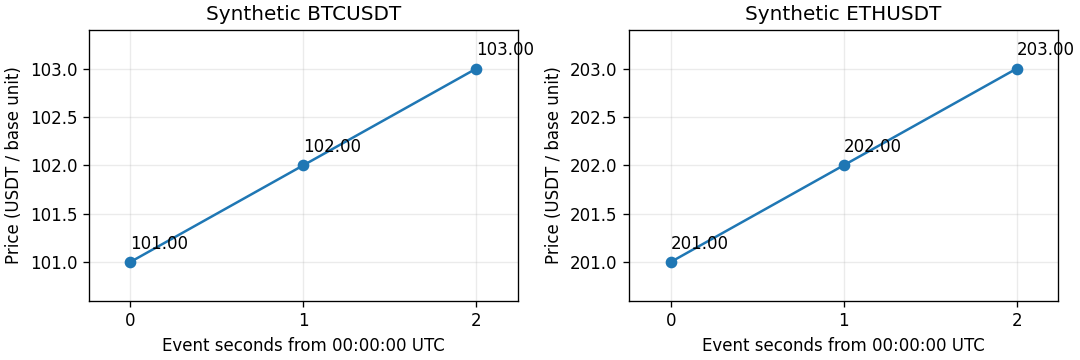

In [24]:
class EdaPlot:
    """Retain only this six-point teaching sample and its append-only attempt log."""

    def __init__(self) -> None:
        """Start a bounded plot buffer separate from the streaming summary."""
        self.points: dict[str, list[tuple[int, Decimal]]] = {}

    def consume(self, batch: QueryBatch) -> None:
        """Observe exact prices; convert to floats only at the plotting boundary.

        Args:
            batch: One batch from the selected synthetic query.
        """
        for row in batch.rows:
            if isinstance(row, QueryMarketRow):
                revision = row.values[3]
                assert isinstance(revision, TradeRevision)
                event = revision.occurrences[0].event
                assert isinstance(event, ArchiveTrade)
                seconds = (event.ts_event - eda_config.start) // timedelta(seconds=1)
                self.points.setdefault(event.symbol, []).append((seconds, event.price))

    @staticmethod
    def report(record: dict[str, object]) -> None:
        """Retain the complete identity/evidence without exporting market rows.

        Args:
            record: Started, complete or failed EDA attempt.
        """
        with (eda_directory / "notebook-attempts.jsonl").open("ab") as output:
            output.write(codec.encode_json(record) + b"\n")


plot = EdaPlot()
eda_summary = inspect_eda(
    eda_directory / "query.json",
    eda_directory / "snapshots",
    RawStore(eda_directory / "raw"),
    report=plot.report,
    consume=plot.consume,
)
retained = [
    json.loads(line) for line in (eda_directory / "attempts.jsonl").read_text().splitlines()
]
assert eda_summary["summary_identity"] == retained[1]["summary_identity"]
assert eda_summary["rows"] == 6 and eda_summary["batches"] == 3
NotebookDisplay.show_table(
    ("Observation", "Value"),
    [
        (key, eda_summary[key])
        for key in (
            "query_identity",
            "summary_identity",
            "rows",
            "controls",
            "batches",
            "max_batch_rows",
            "query_seconds",
            "duration_seconds",
            "process_peak_rss_bytes",
            "process_input_blocks",
        )
    ],
)
fig, axes = plt.subplots(1, 2, figsize=(9, 3), layout="constrained")
for axis, (symbol, points) in zip(axes, plot.points.items(), strict=True):
    axis.plot([t for t, _ in points], [float(price) for _, price in points], "o-")
    axis.set(
        title=f"Synthetic {symbol}",
        xlabel="Event seconds from 00:00:00 UTC",
        ylabel="Price (USDT / base unit)",
        xticks=[0, 1, 2],
    )
    axis.margins(x=0.12, y=0.20)
    axis.grid(alpha=0.25)
    for second, price in points:
        axis.annotate(str(price), (second, float(price)), xytext=(0, 8), textcoords="offset points")
plot_image = BytesIO()
fig.savefig(plot_image, format="png", dpi=120)
display(Image(data=plot_image.getvalue()))
plt.close(fig)

Each instrument has three rows: BTC prices 101–103 and ETH prices 201–203, in
USDT per base unit. They are summarized separately. The plot selects the final
known revisions at second 30; it does not claim those prices were known at their
event times. Exact decimals are retained in the query, summary and labels; only
plot coordinates use floats.

The standalone query and notebook produce identical query/summary identities.
Changing batch size changes the resolved configuration and batch count, while
semantic identities stay fixed. Full eligibility and degraded-quality evidence
remain in each completed record. RSS is the **whole process lifetime peak**,
not this query's allocation or a memory cap. Input blocks measure OS I/O; zero
can mean cached reads. The separate consumer counts actual application file
opens. These tiny-sample observations are not a performance qualification.

**Extension question:** does projection assume every instrument is spot? The
explicit fixture below represents a synthetic future: 2 contracts × 50 underlying
units/contract × 4200.25 USD/unit = 420025 USD. This checks identity and exact
units only; it implements no futures valuation, margin, expiry or settlement.

In [25]:
replayed = json.loads((eda_directory / "replay.json").read_text())
NotebookDisplay.show_table(
    ("Availability UTC", "Instrument", "Exact price"),
    [tuple(row) for row in replayed["sources"]],
)
assert len(replayed["sources"]) == 6
print("Standalone completed cursor:", replayed["cursor"])
extension = json.loads((eda_directory / "extension.json").read_text())
assert extension["projection_only"] and extension["summary"]["evidence"] == []
assert Decimal(extension["amount"]["value"]) == Decimal("420025.00")
NotebookDisplay.show_table(
    ("Contract observation", "Value"),
    [
        ("Family", extension["family"]),
        ("Native quantity", extension["quantity"]),
        ("Underlying units per contract", extension["units_per_contract"]),
        ("Exact dimensioned amount", extension["amount"]),
        ("Neutral projection rows", extension["summary"]["rows"]),
    ],
)
NotebookDisplay.show_table(
    ("Required refusal", "Reason"), [tuple(row) for row in extension["failures"]]
)
failed_attempts = [record for record in retained if record["status"] == "failed"]
assert len(failed_attempts) == 4 and all("summary_identity" not in row for row in failed_attempts)
print("Failed EDA attempts retained:", len(failed_attempts))
print("Spot/future adapter refusal and wrong-unit multiplication are exercised separately.")

Availability UTC,Instrument,Exact price
2024-06-01T00:00:10Z,11111111-1111-4111-8111-111111111111,101.00
2024-06-01T00:00:10Z,22222222-2222-4222-8222-222222222222,201.00
2024-06-01T00:00:20Z,11111111-1111-4111-8111-111111111111,102.00
2024-06-01T00:00:20Z,22222222-2222-4222-8222-222222222222,202.00
2024-06-01T00:00:30Z,11111111-1111-4111-8111-111111111111,103.00
2024-06-01T00:00:30Z,22222222-2222-4222-8222-222222222222,203.00


Standalone completed cursor: {'clock': '2024-06-01T00:00:30Z', 'identity': 'dc91e18e2b0e6ecef6bd8211469c9db468e811687d80f52b0ff4a5972b9afa8b', 'position': ['2024-06-01T00:00:30Z', 1, '2024-06-01T00:00:00Z', 5, 0]}


Contract observation,Value
Family,synthetic_future
Native quantity,"{'dimension': {'instrument_id': {'uuid_value': '33333333-3333-4333-8333-333333333333'}, 'kind': 'contract'}, 'value': '2'}"
Underlying units per contract,50
Exact dimensioned amount,"{'currency': {'code': 'USD', 'minor_unit': '0.01'}, 'value': '420025.000000000000000000'}"
Neutral projection rows,1


Required refusal,Reason
spot adapter with future product,Invalid enum value 'future' - at `$.jobs[0].product`
lifecycle,Object contains unknown field `lifecycle`
adapter,Object contains unknown field `adapter`
unsupported instrument,EDA requires unique bindings covering selected instruments
byte budget,dataset manifest exceeds max_bytes


Failed EDA attempts retained: 4
Spot/future adapter refusal and wrong-unit multiplication are exercised separately.


The synthetic contract reaches the shared projected-batch summary interface with
its contract identity and explicit dimensional conversion. It is **not admitted
to the spot snapshot reader or replay**. Unknown lifecycle/adapter fields, a future
product at the spot source boundary, an unsupported instrument, insufficient byte
budget and direct price × contract multiplication all fail explicitly.

This completes MR 21's bounded EDA/extension exercise. Original archive knowledge,
historical eligibility and coverage remain unresolved for real P1 acceptance;
no frozen P1 assumptions changed. The report callback owns retention, and a failed
plot/export callback cannot produce a completed summary. Temporary synthetic stores
and logs are removed below; the retained notebook output and regression fixtures
are versioned, while full run snapshots remain ignored.

Section 12 inspects the configured live-source negotiation using saved input.
No hosted service, feature platform or lifecycle implementation is introduced.

## 12. What did the live source actually promise? (NB 22)

**Question:** does the selected Bitfinex spot R0 session acknowledge the requested
format, preserve receipt precision and expose unsupported subscriptions?

**Sample:** reuse the explicitly identified saved Bitfinex recording from section 2.
The [MR 22 record](../docs/roadmap/mr-22-implementation.md) documents the small real
connection made with the installed candidate. This notebook only reads saved bytes;
it does not open a connection. A different pinned recording is a different observation.

Inspect the source version, sequence negotiation, native subscription and receipt
interval. The source emits JSON messages; `SEQ_ALL` adds a server sequence, while
our selected flags add **no source timestamp**. Local Unix nanoseconds describe
application receipt, not exchange event time or proven nanosecond clock accuracy.


In [26]:
# project library imports
from alpha_research.data.live.book import Wire

negotiation = {}
first_receipt_ns = last_receipt_ns = None
first_sequence = last_sequence = None
for record in CaptureJournal(bitfinex_directory, bitfinex_request).records():
    if record.kind != "frame":
        continue
    first_receipt_ns = first_receipt_ns or record.received_ns
    last_receipt_ns = record.received_ns
    frame = Wire.decode(record.raw)
    if isinstance(frame, dict):
        control = Wire.mapping(frame)
        if control.get("event") in ("info", "conf", "subscribed"):
            negotiation[str(control["event"])] = control
    else:
        sequence = Wire.integer(Wire.array(frame)[2])
        first_sequence = sequence if first_sequence is None else first_sequence
        last_sequence = sequence
assert negotiation["info"]["version"] == 2
assert negotiation["conf"]["flags"] == 65536
assert negotiation["subscribed"]["symbol"] == bitfinex_request.config.symbol
assert negotiation["subscribed"]["prec"] == "R0"
assert summary["last_source_time"] is None
NotebookDisplay.show_table(
    ("Source binding", "Observed value"),
    [
        ("Recording / connection epochs", (bitfinex_request.recording_id, summary["epochs"])),
        ("Capture implementation", bitfinex_request.implementation_identity),
        ("Source info", negotiation["info"]),
        ("Configuration acknowledgement", negotiation["conf"]),
        ("Subscription acknowledgement", negotiation["subscribed"]),
        ("First / last receipt (Unix ns)", (first_receipt_ns, last_receipt_ns)),
        ("First / last server sequence", (first_sequence, last_sequence)),
        ("Heartbeats / gaps", (summary["heartbeats"], summary["gaps"])),
        ("Exchange event timestamp", "Absent; never replaced with receipt time"),
    ],
)

Source binding,Observed value
Recording / connection epochs,"('a5116c5a-b7d6-4e2b-9ee6-c79839c80f43', 1)"
Capture implementation,22c0e38d88691bd0b1141588260465c471bbde0ff432a6bd1d0dab0505000014
Source info,"{'event': 'info', 'version': 2, 'serverId': 'd3fd84fc-d394-4cd9-b87c-6da075bceba6', 'platform': {'status': 1}}"
Configuration acknowledgement,"{'event': 'conf', 'status': 'OK', 'flags': 65536}"
Subscription acknowledgement,"{'event': 'subscribed', 'channel': 'book', 'chanId': 218177, 'symbol': 'tBTCUSD', 'prec': 'R0', 'freq': 'F0', 'len': '25', 'pair': 'BTCUSD'}"
First / last receipt (Unix ns),"(1789548509412864000, 1789548528719669000)"
First / last server sequence,"(1, 373)"
Heartbeats / gaps,"(1, [])"
Exchange event timestamp,Absent; never replaced with receipt time


In [27]:
source_failures = []
for label, raw in (
    ("Unsupported version", b'{"event":"info","version":3}'),
    ("Rejected subscription", b'{"event":"error","code":10300}'),
    (
        "Wrong stream acknowledgement",
        b'{"event":"subscribed","chanId":7,"channel":"trades","symbol":"tBTCUSD",'
        b'"prec":"R0","freq":"F0","len":"25"}',
    ),
    ("Market data before acknowledgement", b"[7,[[1,100,2]],2]"),
):
    decoder = BitfinexBook(bitfinex_config)
    decoder.apply(b'{"event":"conf","status":"OK","flags":65536}')
    decoder.apply(b'[7,"hb",1]')
    assert not decoder.ready and not decoder.acknowledged
    try:
        decoder.apply(raw)
    except ValueError as error:
        source_failures.append((label, str(error)))
    else:
        raise AssertionError(f"Expected source refusal: {label}")
for label, changes in (
    ("Unsupported venue/stream", {"channel": "books"}),
    ("Unsupported funding product", {"symbol": "fUSD"}),
):
    try:
        replace(bitfinex_config, **changes)
    except ValueError as error:
        source_failures.append((label, str(error)))
    else:
        raise AssertionError(f"Expected configuration refusal: {label}")
NotebookDisplay.show_table(("Controlled failure", "Observed refusal"), source_failures)

Controlled failure,Observed refusal
Unsupported version,unsupported Bitfinex WebSocket version
Rejected subscription,Bitfinex unsupported control or subscription error
Wrong stream acknowledgement,Bitfinex subscription mismatch
Market data before acknowledgement,R0 market frame before subscription acknowledgement
Unsupported venue/stream,unsupported venue/channel
Unsupported funding product,Bitfinex capture supports trading pairs only


The acknowledgements bind this one native spot stream to its actual format. A
heartbeat alone proves neither acknowledgement nor a usable book. The failures
above refuse an unsupported version, denied or mismatched subscription, premature
market frame and unsupported product/stream. Regression tests also stall an outbound
subscription: the shared capture deadline cancels it, closes the socket and retains
an unavailable session instead of hanging.

This is private bounded source verification. Server sequences are documented as
beta and establish only the implemented continuity check within a session. There is
no matching-engine completeness, queue-priority, latency, archive availability or
execution claim. The maintained idle timeout is a fail-closed observation limit;
network jitter around the documented 15-second heartbeat can end an idle session.
The [source guide](../docs/data/l3-collectors.md#mr-22-verified-source-contract)
records permissions, rate limits and lifetime assumptions. Canonical book admission
and shared stepping remain MR 25/27 work; deployment still requires R1.

Section 13 now tests the durable append boundary independently of source access.


## 13. Which received messages survived interruption? (NB 23)

**Question:** can a complete line on disk be mistaken for an acknowledged message?
This synthetic Bitfinex spot R0 sample uses exact message bytes and nanosecond
receipt integers. One bounded journal is one recording segment; its durable cursor
binds the request, byte prefix and message count. Each append commits before the
existing replay consumer validates schema and native price/quantity units.

Predict what interrupted replay will expose after a failed fsync leaves a complete
JSON line beyond the cursor. The checkpoint opens no network connection.


In [28]:
# standard library imports
from unittest.mock import patch
from uuid import uuid4

# project library imports
from alpha_research.data.live.journal import CaptureCursor
from alpha_research.pipelines.live import InstalledIdentity

capture_request = CaptureRequest(
    config=bitfinex_config,
    recording_id=str(uuid4()),
    implementation_identity=InstalledIdentity.sha256(),
)
capture_root = local / "durable-capture"
capture_journal = CaptureJournal(capture_root, capture_request)
capture_journal.start()
capture_consumer = CaptureReplay(bitfinex_config)
capture_records = [CaptureRecord(kind="session", epoch=0, received_ns=1789663921432175123)]
synthetic_frames = (
    b'{"event":"conf","status":"OK","flags":65536}',
    b'{"event":"subscribed","chanId":7,"channel":"book","symbol":"tBTCUSD",'
    b'"prec":"R0","freq":"F0","len":"25"}',
    b"[7,[[1,100.00,2],[2,101.00,-1]],1]",
)
capture_rows = []
for index, raw in enumerate(synthetic_frames, 1):
    capture_records.append(
        CaptureRecord(kind="frame", epoch=0, received_ns=1789663921432175123 + index, raw=raw)
    )
for record in capture_records:
    capture_journal.append(record)
    cursor = codec.decode_json((capture_root / "cursor.json").read_bytes(), CaptureCursor)
    outcome = capture_consumer.apply(record)
    capture_rows.append((cursor.records, cursor.offset, record.received_ns, outcome, record.raw))
assert capture_consumer.book.ready and len(capture_consumer.book.orders) == 2
assert list(capture_journal.records(completed=False))[:-1] == capture_records
NotebookDisplay.show_table(
    ("Committed records", "Byte boundary", "Receipt Unix ns", "Consumer result", "Exact message"),
    capture_rows,
)
print("Committed prefix SHA-256:", cursor.sha256)
print("Bound request identity:", cursor.request_identity)

Committed records,Byte boundary,Receipt Unix ns,Consumer result,Exact message
1,84,1789663921432175123,session,b''
2,226,1789663921432175124,control,"b'{""event"":""conf"",""status"":""OK"",""flags"":65536}'"
3,448,1789663921432175125,control,"b'{""event"":""subscribed"",""chanId"":7,""channel"":""book"",""symbol"":""tBTCUSD"",""prec"":""R0"",""freq"":""F0"",""len"":""25""}'"
4,578,1789663921432175126,snapshot,"b'[7,[[1,100.00,2],[2,101.00,-1]],1]'"


Committed prefix SHA-256: 4a14282a01b8be317bdeba370e2693e399a642a5eaac805354bf7572618db465
Bound request identity: aa258285d61589b4004266e5a7260fd507b091427a1aebdfcbd94ecf685a9ed4


The three source messages retain their grouping and exact decimal text. The
receipt integers differ by one nanosecond here because this is a constructed
example, not a measurement of physical clock accuracy. A cursor advances only
after journal fsync and atomic cursor publication. Receipt continues through the
bounded queue while the downstream replay operation runs outside its event loop.


In [29]:
uncommitted = CaptureRecord(
    kind="frame", epoch=0, received_ns=1789663921432175127, raw=b'[7,"hb",2]'
)
with patch("alpha_research.data.live.journal.os.fsync", side_effect=OSError("synthetic disk full")):
    try:
        capture_journal.append(uncommitted)
    except OSError as error:
        print("Append refused:", error)
    else:
        raise AssertionError("Failed fsync was acknowledged")
assert codec.decode_json((capture_root / "cursor.json").read_bytes(), CaptureCursor) == cursor
assert (capture_root / "journal.jsonl").stat().st_size > cursor.offset
assert list(capture_journal.records(completed=False))[:-1] == capture_records
interrupted = CaptureReplay.read(capture_root, completed=False)
assert interrupted.messages == 3 and interrupted.invalid and not interrupted.ended
print("Complete uncommitted frame excluded; replayed source messages:", interrupted.messages)
print("Visible interruption:", interrupted.gaps[-1])

# Replace only this synthetic uncommitted suffix with a torn write.
capture_path = capture_root / "journal.jsonl"
committed_bytes = capture_path.read_bytes()[: cursor.offset]
capture_path.write_bytes(committed_bytes + b'{"kind":"frame"')
assert list(capture_journal.records(completed=False))[:-1] == capture_records
print("Torn uncommitted frame excluded at the same durable boundary")

capture_failures = []
for label, operation in (
    ("Reuse failed writer", lambda: capture_journal.append(uncommitted)),
    ("Publish failed writer", lambda: capture_journal.finish(capture_records[0].received_ns)),
    ("Overwrite prior recording", lambda: CaptureJournal(capture_root, capture_request).start()),
):
    try:
        operation()
    except OSError as error:
        capture_failures.append(
            (
                label,
                type(error).__name__,
                str(error).replace(str(capture_root), "<synthetic recording>"),
            )
        )
    else:
        raise AssertionError(f"Accepted {label}")
capture_path.write_bytes(committed_bytes[:-1])
try:
    next(capture_journal.records(completed=False))
except ValueError as error:
    capture_failures.append(("Truncated committed prefix", type(error).__name__, str(error)))
else:
    raise AssertionError("Exposed a damaged committed record")
NotebookDisplay.show_table(("Required refusal", "Category", "Reason"), capture_failures)
assert len(capture_failures) == 4

Append refused: synthetic disk full
Complete uncommitted frame excluded; replayed source messages: 3
Visible interruption: {'epoch': 0, 'received_ns': 1789663921432175126, 'reason': 'interrupted_persistence_unknown_tail'}
Torn uncommitted frame excluded at the same durable boundary


Required refusal,Category,Reason
Reuse failed writer,OSError,capture writer is not active; start a new recording
Publish failed writer,OSError,capture writer is not active; cannot publish
Overwrite prior recording,FileExistsError,[Errno 17] File exists: '<synthetic recording>'
Truncated committed prefix,ValueError,committed capture prefix is truncated


In [30]:
restart_request = replace(capture_request, recording_id=str(uuid4()))
restart_journal = CaptureJournal(local / "restart-capture", restart_request)
restart_journal.start()
restart_consumer = CaptureReplay(bitfinex_config)
for record in capture_records:
    restart_journal.append(record)
    restart_consumer.apply(record)
invalid_record = replace(uncommitted, raw=b"[7,[1,100,0],2]")
restart_journal.append(invalid_record)
assert restart_consumer.apply(invalid_record) == "invalid_frame"
assert restart_consumer.invalid and not restart_consumer.book.ready
assert list(restart_journal.records(completed=False))[-2] == invalid_record
assert restart_request.identity != capture_request.identity
assert capture_path.read_bytes() == committed_bytes[:-1]
print("Same-day restart has a distinct request; the interrupted recording is unchanged")
print("Invalid zero-size order retained exactly:", invalid_record.raw)
print("Schema/unit diagnosis blocks consumer:", restart_consumer.gaps[-1])

Same-day restart has a distinct request; the interrupted recording is unchanged
Invalid zero-size order retained exactly: b'[7,[1,100,0],2]'
Schema/unit diagnosis blocks consumer: {'epoch': 0, 'received_ns': 1789663921432175127, 'reason': 'invalid_frame'}


A complete line beyond the cursor is uncommitted. A truncated committed prefix
fails before exposing any record. Disk failure closes the writer; restart creates
a distinct recording rather than appending to an uncertain tail. Invalid native
frames are retained for diagnosis and cannot create a usable book.

Retained regressions additionally kill a child process, inject every checkpoint
fsync/rename failure and block a consumer until the one-slot queue overflows.
The overflow stops receipt with explicit unknown loss; accepted records stay
within the cursor. This does not provide reconnect reconciliation, uninterrupted
service, consumer-state recovery or exactly-once delivery. Old captures without
cursors remain readable, but their interrupted newline prefixes have no cursor
acknowledgement guarantee. No new latency/throughput qualification is claimed.

**Next roadmap MR: 24 — Recover sessions without hiding gaps.** Section 14 exercises the MR 16 handoff; MR 24 is not started here.


## 14. Can acquisition feed publication directly? (MR 16 follow-up)

This checkpoint starts with one configured BTC/ETH universe. It invokes the
installed acquisition command with synthetic checksummed HTTP responses, interrupts
before ETH, and resumes using BTC's saved bytes and clocks. The resulting **whole
acquisition manifest** feeds the installed dataset command without manual splitting.

The same retained [integration consumer](../tests/fixtures/mr16/ingestion_workflow.py)
refuses incomplete acquisition and an interrupted snapshot before retry, then
reopens the published ID and runs the existing EDA workflow. All persistence,
normalization, correction/eligibility/quality contracts and queries are real;
no network connection or source evidence is claimed.


In [31]:
handoff_inputs = local / "handoff-inputs"
handoff_inputs.mkdir()
for source in (
    root / "tests/fixtures/mr16/ingestion_workflow.py",
    root / "tests/fixtures/mr16/interrupt_command.py",
    root / "tests/fixtures/mr12/eligibility.json",
    root / "configs/data-jobs/binance-archive.json",
    root / "configs/reference/binance-archive-spot.json",
):
    shutil.copyfile(source, handoff_inputs / source.name)
handoff_directory = local / "handoff"
handoff_process = subprocess.run(
    [
        sys.executable,
        "-I",
        str(handoff_inputs / "ingestion_workflow.py"),
        str(handoff_inputs),
        str(handoff_directory),
    ],
    cwd=local,
    capture_output=True,
    text=True,
    check=False,
    timeout=60,
)
assert handoff_process.returncode == 0, (handoff_process.stdout, handoff_process.stderr)
handoff = json.loads((handoff_directory / "result.json").read_text())
NotebookDisplay.show_table(
    ("Check", "Observed result"),
    [
        (key, handoff[key])
        for key in (
            "snapshot_id",
            "partitions",
            "scope",
            "history_rows",
            "cutoff_rows",
            "duplicate_counts",
            "fetches",
            "resume_preserved_first_descriptor",
            "repeat_fetches",
        )
    ],
)
handoff_commands = [
    json.loads(line) for line in (handoff_directory / "commands.jsonl").read_text().splitlines()
]
assert [record["exit_code"] for record in handoff_commands if record["exit_code"]] == [
    130,
    3,
    75,
    4,
]
NotebookDisplay.show_table(
    ("Required failure", "Exit", "Result"),
    [
        ("Acquisition interrupted before ETH", 130, "BTC descriptor survives resume"),
        ("Publish incomplete universe", handoff["incomplete_publish_exit"], "No snapshot"),
        (
            "Process stops before publication rename",
            handoff["interrupted_publish_exit"],
            "No visible candidate",
        ),
        ("Inspect interrupted candidate", 4, "Refused; retry publishes the same ID"),
    ],
)

Check,Observed result
snapshot_id,894f5ac3b86fb2aba3a8c8957195a8c3c7017fdd66db2410281d720358efd90e
partitions,2
scope,exploratory_degraded
history_rows,6
cutoff_rows,0
duplicate_counts,"[1, 1]"
fetches,4
resume_preserved_first_descriptor,True
repeat_fetches,0


Required failure,Exit,Result
Acquisition interrupted before ETH,130,BTC descriptor survives resume
Publish incomplete universe,3,No snapshot
Process stops before publication rename,75,No visible candidate
Inspect interrupted candidate,4,Refused; retry publishes the same ID


The complete acquisition becomes two canonical partitions in request order.
Each duplicate retains its raw lineage but contributes one economic trade: six
history rows total. Repeating acquisition makes zero new source requests;
repeating publication preserves snapshot identity. The original checkpoint remains
unchanged for future resume.

Zero cutoff rows are intentional: download clocks do not establish historical
availability. Scope remains `exploratory_degraded`. Tests additionally verify
correction routing, unused/cross-instrument links, missing/corrupt later inputs,
strict schemas and overlap refusal. This follow-up adds no live/book admission,
causal evidence, source adapter or multi-day scheduler.


In [32]:
# All synthetic files belong to this run; the saved book inputs were only read.
workspace.cleanup()